## Homework 4

> [!NOTE]
> This homework uses the pinned 2026 lead-scoring release in the course
> repository. The plan and report are available in `cohorts/2026/data/`.


In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).


In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not. 



### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```


In [123]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "hlib").is_dir():
    REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT))

In [124]:
import pandas as pd
from sklearn.model_selection import train_test_split
from hlib.data import ModelData, split_feature_target_columns
from sklearn.metrics import roc_auc_score, roc_curve

In [125]:
PROJECT_FOLDER = REPO_ROOT / "homework_4"
DATA_PATH = PROJECT_FOLDER / "course_lead_scoring_2026.csv"

In [126]:

DF = pd.read_csv(DATA_PATH)
df = DF.copy()

target_cols = ['converted']
feature_cols = [
    c for c in df.columns
    if c != "converted"
]

num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(include=["str", "object"]).columns

df[num_cols] = df[num_cols].fillna(0.0)
df[cat_cols] = df[cat_cols].fillna('NA')

df.isna().any()

lead_source                 False
industry                    False
employment_status           False
location                    False
annual_income               False
number_of_courses_viewed    False
interaction_count           False
lead_score                  False
converted                   False
dtype: bool

In [127]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [128]:
D = ModelData(
    train=split_feature_target_columns(df_train, target_cols),
    val=split_feature_target_columns(df_val, target_cols),
    test=split_feature_target_columns(df_test, target_cols),
)



### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`



In [129]:
try:
    D.train.features[num_cols]
except KeyError as e:
    print(e,"\n Target columns in features; dropping: ", target_cols)
    D.train.features[num_cols.drop(target_cols)]

dfn = D.train.features[num_cols.drop(target_cols)]
tn = D.train.targets

tn.values.ravel()



"['converted'] not in index" 
 Target columns in features; dropping:  ['converted']


array([1, 0, 0, ..., 0, 1, 1], shape=(3000,))

In [130]:
# dfn = df_train[num_cols.drop(target_cols)]
# tn = df_train[target_cols]

In [131]:
res = {}
for col in dfn.columns:
    # print(dfn[col])
    auc  = roc_auc_score(tn.values.ravel(), dfn[col].values)
    res[col] = auc

max(res.items(), key=lambda x: x[1])

('lead_score', 0.7882254810906102)



### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832


In [132]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction import DictVectorizer

In [133]:
dv = DictVectorizer(sparse=False)


In [134]:

# train_dict = df_train[feature_cols].to_dict(orient='records')
# x_train = dv.fit_transform(train_dict)
# y_train = df_train[target_cols].values.ravel()

# val_dict = df_val[feature_cols].to_dict(orient="records")
# test_dict = df_test[feature_cols].to_dict(orient="records")

# x_val = dv.transform(val_dict)
# x_test = dv.transform(test_dict)

# y_val = df_val[target_cols].values.ravel()
# y_test = df_test[target_cols].values.ravel()

train_dict = D.train.features[feature_cols].to_dict(orient="records")
D.train.X = dv.fit_transform(train_dict)

val_dict = D.val.features[feature_cols].to_dict(orient="records")
test_dict = D.test.features[feature_cols].to_dict(orient="records")

D.val.X = dv.transform(val_dict)
D.test.X = dv.transform(test_dict)


In [135]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

# model.fit(x_train, y_train)
model.fit(D.train.X,D.train.y.ravel())

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [136]:
res = {}
y_pred = model.predict_proba(D.val.X)[:,1]
y_val = D.val.y.ravel()
# y_pred = model.predict_proba(x_val)[:,1]
auc = roc_auc_score(y_val, y_pred)

res['base'] = dict(auc=auc,C=1.0,solver='liblinear',max_iter=1000)


In [137]:
round(res['base']['auc'],3)

0.732



### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83


In [138]:
import numpy as np

In [139]:
thresholds = np.arange(0,1,0.01)
records = []
for t in thresholds:

    actual_positives = (y_val == 1)
    actual_negatives = (y_val == 0)

    predicted_positives = (y_pred >= t)
    predicted_negatives = (y_pred < t)

    record = (
        t,                                             # threshold 
        (actual_positives & predicted_positives).sum(),# true positives
        (actual_negatives & predicted_negatives).sum(),# true negatives
        (actual_negatives & predicted_positives).sum(),# false positives
        (actual_positives & predicted_negatives).sum(),# false negatives
    ) 

    records.append(record)

columns = ['threshold', 'tp', 'tn', 'fp', 'fn']
df_scores = pd.DataFrame(records, columns=columns)

df_scores['precision'] = df_scores['tp']/(df_scores['tp']+df_scores['fp'])
df_scores['recall'] = df_scores['tp']/(df_scores['tp']+df_scores['fn'])

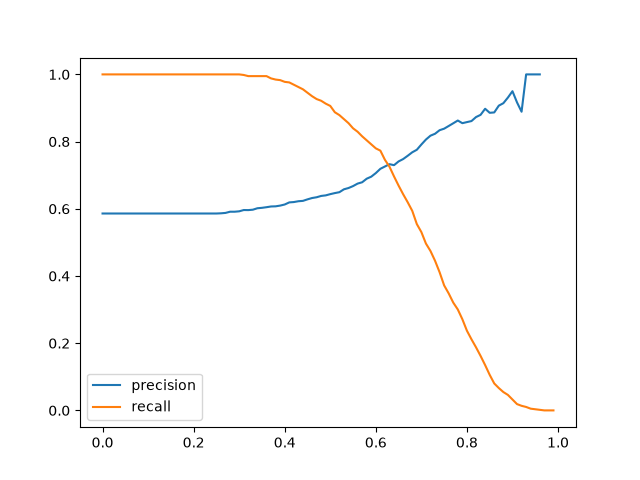

In [140]:
%matplotlib widget
import matplotlib.pyplot as plt

plt.figure()
plt.plot(df_scores['threshold'],df_scores['precision'], label = 'precision')
plt.plot(df_scores['threshold'],df_scores['recall'], label = 'recall')
plt.legend()

plt.show()

In [141]:
np.isclose

<function isclose at 0x7013d21abd30>

In [142]:
df_scores.loc[np.isclose(df_scores.recall, df_scores.precision,atol = 0.01)]

,threshold,tp,tn,fp,fn,precision,recall
63,0.63,425,259,155,161,0.732759,0.725256




### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81


In [143]:
P,R = df_scores.precision, df_scores.recall
df_scores['f1'] = 2 * (P*R)/(P+R)

df_scores.f1.max().round(3),df_scores.loc[df_scores.f1.idxmax(),'threshold'].round(3)

(np.float64(0.758), np.float64(0.41))



### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060



In [144]:
from sklearn.model_selection import KFold

In [149]:
def training(D: ModelData, 
             feature_cols: list[str], 
             target_cols: list[str],
             C=1.0):
    dv = DictVectorizer(sparse=False)
    train_dict = D.train.features[feature_cols].to_dict(orient="records")
    D.train.X = dv.fit_transform(train_dict)

    model = LogisticRegression(
        solver='liblinear', 
        C=C, 
        max_iter=1000
        )

    # model.fit(x_train, y_train)
    model.fit(D.train.X,D.train.y.ravel())

    return dv, model

def scoring(D, dv, model, feature_cols):
    val_dict = D.val.features[feature_cols].to_dict(orient="records")
    D.val.X = dv.transform(val_dict)
    y_pred = model.predict_proba(D.val.X)[:,1]
    y_val = D.val.y.ravel()
    auc = roc_auc_score(y_val, y_pred)
    return auc
    # res = {}
    # y_pred = model.predict_proba(D.val.X)[:,1]
    # y_val = D.val.y.ravel()
    # # y_pred = model.predict_proba(x_val)[:,1]
    # auc = roc_auc_score(y_val, y_pred)

    # res['base'] = dict(auc=auc,C=1.0,solver='liblinear',max_iter=1000)
    # return auc, res

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)

aucs = []

for i, (train_index, val_index) in enumerate(kf.split(df_full_train)):
    # print(f"Fold {i}:")
    df_train_fold, df_val_fold = (
        df_full_train.iloc[train_index],
        df_full_train.iloc[val_index]
    )
    D = ModelData(
        split_feature_target_columns(df_train_fold, target_cols),
        split_feature_target_columns(df_val_fold, target_cols),
        split_feature_target_columns(df_test, target_cols)
    )
    dv, model = training(D, feature_cols, target_cols)
    auc = scoring(D=D, 
                  model=model, 
                  dv=dv, 
                  feature_cols=feature_cols)
    aucs.append(auc)

    # print(f"  Train: index={train_index[:10]}")
    # print(f"  Test:  index={test_index[:10]}")

In [151]:
np.round(np.std(aucs),3)

np.float64(0.007)


### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.


In [154]:
def kf_iter(kf, df_full_train, feature_cols, target_cols,C):
    aucs = []

    for _, (train_index, val_index) in enumerate(kf.split(df_full_train)):
        # print(f"Fold {i}:")
        df_train_fold, df_val_fold = (
            df_full_train.iloc[train_index],
            df_full_train.iloc[val_index]
        )
        D = ModelData(
            split_feature_target_columns(df_train_fold, target_cols),
            split_feature_target_columns(df_val_fold, target_cols),
            split_feature_target_columns(df_test, target_cols)
        )
        dv, model = training(D, feature_cols, target_cols,C=C)
        auc = scoring(D=D, 
                    model=model, 
                    dv=dv, 
                    feature_cols=feature_cols)
        aucs.append(auc)
    return aucs

In [157]:
aucs = {}
for C in [0.000001, 0.001, 1]:
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs_fold = kf_iter(kf,df_full_train,feature_cols,target_cols,C)
    aucs[C] = {
        'mean':np.mean(aucs_fold),
        'std': np.std(aucs_fold),
        'values': aucs_fold
    }
    

In [162]:
aucs

{1e-06: {'mean': np.float64(0.6167342250714795),
  'std': np.float64(0.018669799234831475),
  'values': [0.5941004654148612,
   0.6402137243565715,
   0.6001570384100505,
   0.6364466933726896,
   0.6127532038032245]},
 0.001: {'mean': np.float64(0.7491721776030379),
  'std': np.float64(0.009996375455700753),
  'values': [0.7504349221633766,
   0.7475333388395098,
   0.7583539285346514,
   0.7584127166669861,
   0.7311259818106656]},
 1: {'mean': np.float64(0.7317269710972524),
  'std': np.float64(0.006853233151022138),
  'values': [0.7305601027122453,
   0.7295726148196622,
   0.7363428071259397,
   0.7412454717957564,
   0.7209138590326581]}}

In [164]:
# main_key, inner = max(data.items(), key=lambda item: item[1]["key2"])

C_best, best_mean_dict = max(aucs.items(), key=lambda x: x[1]['mean'])

C_best, best_mean_dict['mean']

(0.001, np.float64(0.7491721776030379))


## Learning in Public

Share what you learned from this homework in a short post, screenshot, or
notebook excerpt. Use `#mlzoomcamp`, tag Alexey Grigorev or DataTalksClub, and
submit the post link with your homework. Don't share credentials, private
data, or other secrets.

See the [learning in public guide](https://datatalks.club/docs/courses/zoomcamp-logistics/learning-in-public/) for more
ideas and examples.

### Example post for LinkedIn

```text
🚀 Completed Module 4 of Machine Learning Zoomcamp 2026!

I evaluated a classifier with ROC AUC, precision, recall, and F1, then used
cross-validation to measure score variation and tune a parameter.

My repo: <LINK>

#mlzoomcamp @Alexey Grigorev
```

### Example post for X

```text
Evaluated a classifier in Module 4 of #mlzoomcamp.

✅ Compared ROC AUC and threshold-based metrics
✅ Found a useful precision/recall trade-off
✅ Used 5-fold cross-validation for tuning

My repo: <LINK>
```

## Submit the results

* Submit your results here: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04
* The numerical options are calculated from the pinned 2026 release. Use the value that matches your calculation; do not choose a merely close value.